In [1]:
import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score


In [2]:
# Constants
SEED = 42
DATA_FILE = "FordA_TRAIN.tsv"      # tab-separated, no header, column 0 = label (1 / -1), columns 1.. = series
TEST_SIZE = 0.20                   # share of the file held out for testing
VAL_SIZE = 0.20                    # share of the file used for validation (train gets the remaining 60%)
EPOCHS = 30
BATCH_SIZE = 32
PATIENCE = 5                       # early stopping on validation loss
LEARNING_RATE = 0.001
CLASS_NAMES = ["No fault", "Fault"]
USE_GPU = True                     # True = use the NVIDIA GPU if TensorFlow can see one, False = force CPU


In [3]:
# GPU setup
gpus = tf.config.list_physical_devices("GPU")
if USE_GPU and gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)    # don't grab all GPU memory up front
    DEVICE_NAME = "GPU: " + ", ".join(g.name for g in gpus)
else:
    if gpus:
        tf.config.set_visible_devices([], "GPU")               # USE_GPU = False -> hide the GPU
    DEVICE_NAME = "CPU"
    if USE_GPU:
        print("WARNING: no GPU visible to TensorFlow, running on CPU.\n"
              "  - Native Windows: TensorFlow >= 2.11 has no GPU support, use WSL2 (Ubuntu) or a Linux machine.\n"
              "  - Linux / WSL2: pip install 'tensorflow[and-cuda]' and make sure the NVIDIA driver works (nvidia-smi).")
print("TensorFlow", tf.__version__, "| running on", DEVICE_NAME)

tf.keras.utils.set_random_seed(SEED)

  - Native Windows: TensorFlow >= 2.11 has no GPU support, use WSL2 (Ubuntu) or a Linux machine.
  - Linux / WSL2: pip install 'tensorflow[and-cuda]' and make sure the NVIDIA driver works (nvidia-smi).
TensorFlow 2.20.0 | running on CPU


In [4]:
def load_forda(filename):
    # Load Tab separated value file
    data = pd.read_csv(filename, sep="\t", header=None).to_numpy(dtype=np.float32)
    raw_labels = data[:, 0]
    # Check if all rows are labelled with a 1/-1 
    assert set(np.unique(raw_labels[~np.isnan(raw_labels)])) <= {-1.0, 1.0}, "labels must be 1 or -1"
    # Convert to 1 = fault, 0 = no fault (original -1)
    y = (raw_labels == 1).astype(int)
    return data[:, 1:], y


X_all, y_all = load_forda(DATA_FILE)
SERIES_LEN = X_all.shape[1]
print("Full file:", X_all.shape)

# First hold out the test set, then split the rest into train and validation (both stratified).
# Each series is an independent labelled sample, so a random stratified split is used.
X_rest_raw, X_test_raw, y_rest, y_test = train_test_split(
    X_all, y_all, test_size=TEST_SIZE, random_state=SEED, stratify=y_all
)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_rest_raw, y_rest, test_size=VAL_SIZE / (1 - TEST_SIZE), random_state=SEED, stratify=y_rest
)
print("Train:", X_train_raw.shape, "| Val:", X_val_raw.shape, "| Test:", X_test_raw.shape)


Full file: (3601, 500)
Train: (2160, 500) | Val: (720, 500) | Test: (721, 500)


# Data exploration

In [5]:
# Target: fault indicator, 1 = fault, -1 = no fault (recoded to 1 / 0)
# Unit and native sampling frequency are NOT given in the file
def audit(X, y, name):
    rows = [x.tobytes() for x in X]
    return {
        "split": name,
        "series": len(X),
        "length": X.shape[1],
        "missing values": int(np.isnan(X).sum()),
        "duplicate series": len(rows) - len(set(rows)),
        "constant series": int((np.nanstd(X, axis=1) == 0).sum()),
        "fault share": round(float(y.mean()), 3),
        "min": round(float(np.nanmin(X)), 2),
        "max": round(float(np.nanmax(X)), 2),
    }


audit_table = pd.DataFrame([audit(X_all, y_all, "full file"),
                            audit(X_train_raw, y_train, "train"),
                            audit(X_val_raw, y_val, "validation"),
                            audit(X_test_raw, y_test, "test")]).set_index("split")
print(audit_table.T)

split             full file     train  validation     test
series             3601.000  2160.000     720.000  721.000
length              500.000   500.000     500.000  500.000
missing values        0.000     0.000       0.000    0.000
duplicate series      0.000     0.000       0.000    0.000
constant series       0.000     0.000       0.000    0.000
fault share           0.487     0.487       0.487    0.487
min                  -4.620    -4.620      -4.210   -4.370
max                   5.060     5.060       4.450    4.350


In [6]:
split_table = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "source": [f"{1 - VAL_SIZE - TEST_SIZE:.0%} of the file (fit models)",
               f"{VAL_SIZE:.0%} of the file (early stopping, model selection)",
               f"{TEST_SIZE:.0%} of the file (final evaluation only)"],
    "series": [len(X_train_raw), len(X_val_raw), len(X_test_raw)],
    "fault share": [y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3)],
})
print(split_table)

        split                                             source  series  \
0       train                       60% of the file (fit models)    2160   
1  validation  20% of the file (early stopping, model selection)     720   
2        test            20% of the file (final evaluation only)     721   

   fault share  
0        0.488  
1        0.488  
2        0.487  


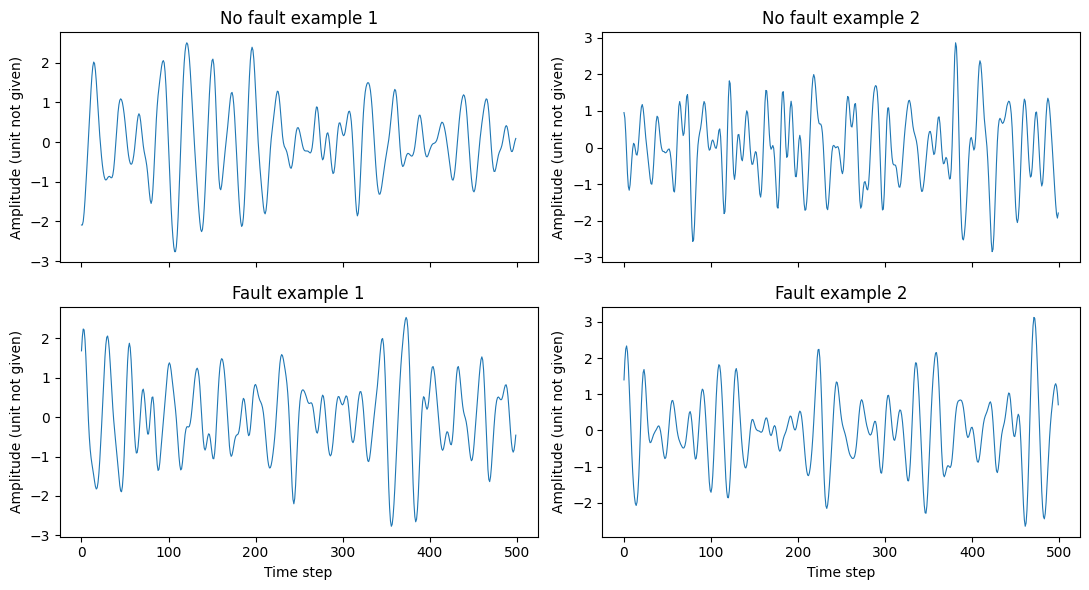

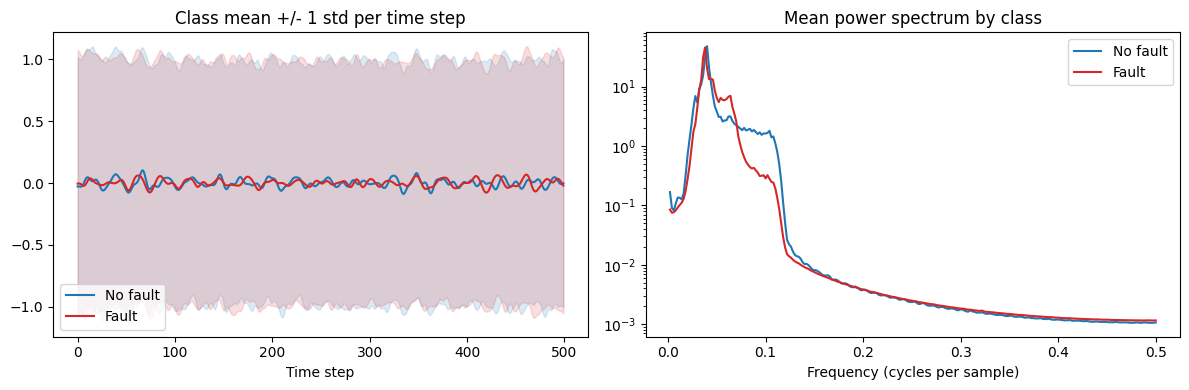

In [7]:
# Data visualization using training dataset

# Figure 1: example series per class
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for label in [0, 1]:
    for j, idx in enumerate(np.where(y_train == label)[0][:2]):
        axes[label, j].plot(X_train_raw[idx], lw=0.8)
        axes[label, j].set_title(f"{CLASS_NAMES[label]} example {j + 1}")
        axes[label, j].set_ylabel("Amplitude (unit not given)")
for ax in axes[-1]:
    ax.set_xlabel("Time step")
plt.tight_layout()
plt.savefig("fig1_examples.png", dpi=150)
plt.show()

# Figure 2: class mean +/- std per time step, and mean power spectrum per class
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, color in [(0, "tab:blue"), (1, "tab:red")]:
    Xc = X_train_raw[y_train == label]
    m, s = Xc.mean(axis=0), Xc.std(axis=0)
    axes[0].plot(m, color=color, label=CLASS_NAMES[label])
    axes[0].fill_between(np.arange(SERIES_LEN), m - s, m + s, color=color, alpha=0.15)

    Xc0 = Xc - Xc.mean(axis=1, keepdims=True)
    power = (np.abs(np.fft.rfft(Xc0, axis=1)) ** 2 / SERIES_LEN).mean(axis=0)
    axes[1].semilogy(np.fft.rfftfreq(SERIES_LEN)[1:], power[1:], color=color, label=CLASS_NAMES[label])
    
axes[0].set_title("Class mean +/- 1 std per time step")
axes[0].set_xlabel("Time step")
axes[0].legend()
axes[1].set_title("Mean power spectrum by class")
axes[1].set_xlabel("Frequency (cycles per sample)")
axes[1].legend()
plt.tight_layout()
plt.savefig("fig2_class_mean_and_spectrum.png", dpi=150)
plt.show()

### Analysis
The exploratory analysis of the time-series dataset suggests that fault and no-fault signals are hard to tell apart in the time domain but show a measurable difference in the frequency domain. This suggests that a spectrogram or FFT input may be good options to consider for the extra analysis.

Based on the graphed samples above, the data in this dataset are stationary and and stable since it stays around 0 and there are no large spikes.

# Model Buliding

In [ ]:
imputer = SimpleImputer(strategy="median").fit(X_train_raw)
scaler = StandardScaler().fit(imputer.transform(X_train_raw))

# Normalize and impute
def preprocess(X):
    return scaler.transform(imputer.transform(X)).astype("float32")

X_train_flat, X_val_flat, X_test_flat = preprocess(X_train_raw), preprocess(X_val_raw), preprocess(X_test_raw)

# Conv1D expects: samples x time x channels
X_train_cnn = X_train_flat[..., np.newaxis]
X_val_cnn = X_val_flat[..., np.newaxis]
X_test_cnn = X_test_flat[..., np.newaxis]

# Input window = the whole series; no forecast horizon (one label per series)
print("Baselines / MLP input shape:", X_train_flat.shape, X_val_flat.shape, X_test_flat.shape)
print("CNN input shape:            ", X_train_cnn.shape, X_val_cnn.shape, X_test_cnn.shape)
print("Target shape:               ", y_train.shape, y_val.shape, y_test.shape)

INPUTS = {"flat": (X_train_flat, X_val_flat, X_test_flat),
          "cnn": (X_train_cnn, X_val_cnn, X_test_cnn)}


Baselines / MLP input shape: (2160, 500) (720, 500) (721, 500)
CNN input shape:             (2160, 500, 1) (720, 500, 1) (721, 500, 1)
Target shape:                (2160,) (720,) (721,)


In [9]:
def scores(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {"acc": accuracy_score(y_true, pred),
            "f1": f1_score(y_true, pred, zero_division=0),
            "auc": roc_auc_score(y_true, prob)}


def compile_model(model):
    model.compile(optimizer=Adam(learning_rate=LEARNING_RATE),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model


def fresh_start():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)


def train_and_validate(name, model, kind):
    X_tr, X_va, X_te = INPUTS[kind]
    es = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(X_tr, y_train, validation_data=(X_va, y_val),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[es], verbose=0)
    train_seconds = time.perf_counter() - start
    val_prob = model.predict(X_va, verbose=0).ravel()
    return {"name": name, "kind": kind, "model": model, "history": history,
            "params": model.count_params(), "train_s": train_seconds,
            "val": scores(y_val, val_prob)}

In [10]:
def build_mlp(units=64, dropout=0.0):
    return compile_model(Sequential([
        Input(shape=(SERIES_LEN,)),
        Dense(units, activation="relu"),
        Dropout(dropout),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ]))


def build_cnn(filters=8, kernel_size=7):
    return compile_model(Sequential([
        Input(shape=(SERIES_LEN, 1)),
        Conv1D(filters=filters, kernel_size=kernel_size, activation="relu", padding="same"),
        MaxPooling1D(pool_size=4),
        Flatten(),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid"),
    ]))

# Training + Performance

In [ ]:
majority_class = int(np.bincount(y_train).argmax())
print("Majority class:", CLASS_NAMES[majority_class])

# Basline Logistic Regression
start = time.perf_counter()
logreg = LogisticRegression(C=0.1, max_iter=2000).fit(X_train_flat, y_train)
logreg_seconds = time.perf_counter() - start

# Majority baseline
majority_val_prob = np.full(len(y_val), y_train.mean())
majority_test_prob = np.full(len(y_test), y_train.mean())

logreg_val_prob = logreg.predict_proba(X_val_flat)[:, 1]
logreg_test_prob = logreg.predict_proba(X_test_flat)[:, 1]

print("Validation accuracy:\nmajority:", round(scores(y_val, majority_val_prob)["acc"], 3),
      "| logistic regression:", round(scores(y_val, logreg_val_prob)["acc"], 3))


Majority class: No fault
Validation accuracy:
majority: 0.512 | logistic regression: 0.486


In [ ]:
fresh_start()
mlp_default = train_and_validate("MLP (default)", build_mlp(), "flat")
fresh_start()
cnn_default = train_and_validate("CNN (default)", build_cnn(), "cnn")

print("Validation accuracy:\nMLP:", round(mlp_default["val"]["acc"], 3),
      "| CNN:", round(cnn_default["val"]["acc"], 3))

# the better neural family on VALIDATION accuracy is the one we tune
best_family = "MLP" if mlp_default["val"]["acc"] >= cnn_default["val"]["acc"] else "CNN"
print("Model selected for grid search:", best_family)



Validation accuracy  MLP: 0.725 | CNN: 0.879
Model selected for grid search: CNN


   filters  kernel_size  params  epochs  train_s  val_acc  val_auc
0       16           15   32289      13      4.5   0.9083   0.9753
1        8           15   16161      11      3.8   0.8944   0.9644
2        8            7   16097      18      5.4   0.8792   0.9503
3       16            7   32161      15      5.1   0.8611   0.9456
4        8            3   16065      15      5.1   0.7653   0.8374
5       16            3   32097      13      5.0   0.7042   0.7939

Tie-break rule: highest validation accuracy -> fewer parameters
Best configuration: CNN {'filters': 16, 'kernel_size': 15}


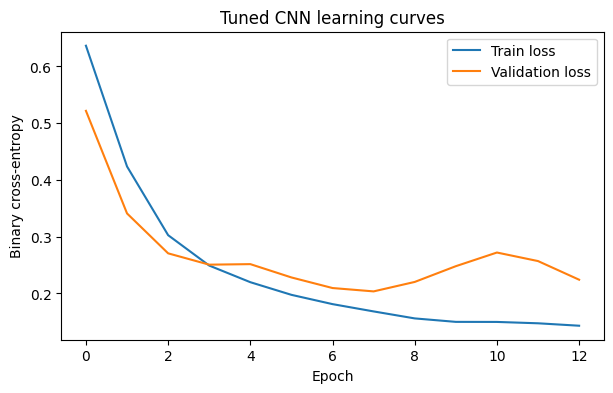

In [ ]:
GRIDS = {
    "MLP": {"units": [32, 64, 128], "dropout": [0.0, 0.3]},
    "CNN": {"filters": [8, 16], "kernel_size": [3, 7, 15]},
}
BUILDERS = {"MLP": (build_mlp, "flat"), "CNN": (build_cnn, "cnn")}

builder, kind = BUILDERS[best_family]
grid = GRIDS[best_family]

# Run grid search
grid_runs, grid_rows = [], []
for values in itertools.product(*grid.values()):
    hp = dict(zip(grid.keys(), values))
    fresh_start()
    run = train_and_validate(f"{best_family} {hp}", builder(**hp), kind)
    grid_runs.append(run)
    grid_rows.append({**hp, "params": run["params"], "epochs": len(run["history"].history["loss"]),
                      "train_s": round(run["train_s"], 1), "val_acc": round(run["val"]["acc"], 4),
                      "val_auc": round(run["val"]["auc"], 4)})

# Display grid search results
grid_table = pd.DataFrame(grid_rows)
order = grid_table.sort_values(["val_acc", "params"], ascending=[False, True]).index   # tie-break: fewer parameters
grid_table = grid_table.loc[order].reset_index(drop=True)
grid_table.to_csv("grid_search_results.csv", index=False)
print(grid_table)

best_run = grid_runs[order[0]]
print("\nTie-break rule: highest validation accuracy -> fewer parameters")
print("Best configuration:", best_run["name"])

# Learning curve of best model
plt.figure(figsize=(7, 4))
plt.plot(best_run["history"].history["loss"], label="Train loss")
plt.plot(best_run["history"].history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title(f"Tuned {best_family} learning curves")
plt.legend()
plt.savefig("fig4_learning_curves.png", dpi=150)
plt.show()


In [ ]:
# Results

# Results for neural network models
def neural_row(label, run):
    X_te = INPUTS[run["kind"]][2]
    test = scores(y_test, run["model"].predict(X_te, verbose=0).ravel())
    return {"Model": label, "Params": run["params"], "Train time (s)": round(run["train_s"], 1),
            "Val acc": round(run["val"]["acc"], 4), "Test acc": test["acc"], "Test F1": test["f1"], "Test AUC": test["auc"]}


# Results for logistic regression + majority models
def baseline_row(label, params, seconds, val_prob, test_prob):
    test = scores(y_test, test_prob)
    return {"Model": label, "Params": params, "Train time (s)": round(seconds, 1),
            "Val acc": round(scores(y_val, val_prob)["acc"], 4),
            "Test acc": test["acc"], "Test F1": test["f1"], "Test AUC": test["auc"]}


results = pd.DataFrame([
    baseline_row("Majority class", 0, 0.0, majority_val_prob, majority_test_prob),
    baseline_row("Logistic regression", SERIES_LEN + 1, logreg_seconds, logreg_val_prob, logreg_test_prob),
    neural_row("MLP (default)", mlp_default),
    neural_row("CNN (default)", cnn_default),
    neural_row(f"{best_family} (tuned)", best_run),
])

majority_acc = results.loc[0, "Test acc"]
logreg_acc = results.loc[1, "Test acc"]
results["Gain vs majority (pp)"] = ((results["Test acc"] - majority_acc) * 100).round(2)
results["Gain vs logistic reg. (pp)"] = ((results["Test acc"] - logreg_acc) * 100).round(2)
results[["Test acc", "Test F1", "Test AUC"]] = results[["Test acc", "Test F1", "Test AUC"]].round(4)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
print(results.to_string(index=False))
print("Training times measured on:", DEVICE_NAME)
results.to_csv("comparison_table.csv", index=False)

              Model  Params  Train time (s)  Val acc  Test acc  Test F1  Test AUC  Gain vs majority (pp)  Gain vs logistic reg. (pp)
     Majority class       0             0.0   0.5125    0.5132   0.0000    0.5000                   0.00                       -0.69
Logistic regression     501             0.1   0.4861    0.5201   0.4956    0.5375                   0.69                        0.00
      MLP (default)   33121             3.1   0.7250    0.7295   0.7303    0.8021                  21.64                       20.94
      CNN (default)   16097             5.4   0.8792    0.8613   0.8588    0.9398                  34.81                       34.12
        CNN (tuned)   32289             4.5   0.9083    0.8849   0.8809    0.9622                  37.17                       36.48
Training times measured on: CPU


### CONCLUSION
The tuned CNN reached test accuracy 0.885 (F1 0.881, AUC 0.962), +37.17 pp vs the majority baseline and +36.48 pp vs logistic regression, using 32,289 parameters and 4.5 s of training (logistic regression: 0.1 s).

### Future Works
The file has no engine or recording identifier, so the random stratified validation split may put near-identical recordings from the same engine in both train and validation. That would inflate validation accuracy and bias the model selection and early stopping. Every neural result also comes from a single seed, so small differences between models may be noise. Next step: repeat with several seeds and with contiguous blocks of the file (first 60% train, next 20% validation, last 20% test), and check whether the model ranking changes.


The window size is also untested. Every model sees the full 500-step series as one window for the sake of simplicity in the initial stages of the project, so we do not know whether the fault signal is spread across the whole recording or concentrated in a short segment. Next step: also vary the window size (e.g. 100, 250 and 500 steps, cut from each series), and compare accuracy and training cost. Shorter windows give more training samples and cheaper models, but each series must be assigned to train, validation or test before it is cut into windows, otherwise windows from the same series leak across splits.